# 02 — Quality Gate V1 | Calibration → Freeze → Test

**Đầu vào:** PCM16 mono, 16 kHz, cửa sổ 5 s (80.000 mẫu), trước chuẩn hóa/DSP. Quality Gate kiểm tra mức tín hiệu, hoạt động và clipping; **không xác nhận có tiếng hô hấp**.

Quy trình: kiểm toán dữ liệu → Calibration → kiểm tra ngưỡng V1 → Freeze → Held-out Test → đối chứng Silence. Notebook lưu output của lần chạy lại; không sử dụng Test để thay đổi ngưỡng.

## 0. Chuẩn bị (PowerShell, trong `02_Quality_Check`)

Sao lưu cả thư mục `results/` cũ (đặc biệt JSON FROZEN, Test) trước khi chạy lại; lưu cả `figures/` nếu cần giữ hình cũ. Thay các file `.py` và notebook bằng bộ này, **không đổi WAV hoặc split**.

```powershell
py -3.11 -m unittest -v test_quality_utils.py
py -3.11 .\Extract_Quality_Metrics.py plan --windows-per-session 2 --with-playback
py -3.11 .\Extract_Quality_Metrics.py calibrate
```

Lưu ý: `plan` yêu cầu đúng `environment_session_split.csv` V2 (33 Environment, chia 27 Train / 3 Val / 3 Test); không tự chia lại. `--with-playback` chỉ bổ sung file `__take01/02` PCM16 đúng định dạng.

In [25]:
from pathlib import Path
import json, sys, subprocess, wave, importlib.util
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

REL = Path('Experiments_Benchmarking/Patient_Node/Final_V1_Validation/02_Quality_Check')
starts = (Path.cwd().resolve(), *Path.cwd().resolve().parents)
HERE = next((d for d in [*starts, *(p / REL for p in starts)]
             if (d / 'Extract_Quality_Metrics.py').is_file()
             and (d / 'quality_utils.py').is_file()), None)
assert HERE is not None, 'Không tìm được folder 02_Quality_Check chứa cả hai Python script'
HERE = HERE.resolve()
REPO_ROOT = next((p for p in (HERE, *HERE.parents)
                  if (p/'AI_Training_Model').is_dir()
                  and (p/'Experiments_Benchmarking').is_dir()
                  and (p/'Final_Project_NCKH').is_dir()), None)
assert REPO_ROOT is not None, 'Không xác định được repository root'
# Nạp đúng quality_utils.py đi cùng notebook; không dùng module cùng tên còn cache từ nơi khác.
QUALITY_UTILS_PATH = HERE/'quality_utils.py'
spec = importlib.util.spec_from_file_location('quality_utils_final_v1', QUALITY_UTILS_PATH)
assert spec is not None and spec.loader is not None, f'Không thể nạp {QUALITY_UTILS_PATH}'
quality_utils = importlib.util.module_from_spec(spec)
sys.modules[spec.name] = quality_utils
spec.loader.exec_module(quality_utils)
QualityThresholds = quality_utils.QualityThresholds
file_sha256 = quality_utils.file_sha256
freeze_config = quality_utils.freeze_config
load_frozen = quality_utils.load_frozen
verify_test_provenance = quality_utils.verify_test_provenance
classify_audio = quality_utils.classify_audio
RESULTS, FIGURES = HERE/'results', HERE/'figures'
MANIFEST, CAL, FINAL, TEST = (RESULTS/'quality_window_manifest.csv',
    RESULTS/'calibration_metrics.csv', RESULTS/'final_quality_gate.json',
    RESULTS/'test_metrics.csv')
assert MANIFEST.is_file() and CAL.is_file(), 'Hãy chạy plan + calibrate trước'
m = pd.read_csv(MANIFEST)
c = pd.read_csv(CAL)
assert len(c) and c.qc_split.eq('calibration').all()
assert set(c.source_group).isdisjoint(set(m.loc[m.qc_split=='test', 'source_group']))
main = m[(m.source_kind=='environment_master') &
         m.subtype.isin(['podcast','fan','clap','knock','room_noise','speech'])]
sessions = main[['session_id','original_split','source_group']].drop_duplicates()
assert len(sessions)==33
assert sessions.original_split.value_counts().to_dict()=={'train':27,'val':3,'test':3}
assert {'silence_old_01','keyfan_old_01'}.issubset(set(m.session_id))
print('PASS inventory/split:', len(sessions), 'main sessions')
print('Calibration windows:',len(c),'| Test windows (chưa đọc tín hiệu):',int(m.qc_split.eq('test').sum()))
display(c.groupby('subtype').agg(windows=('rms','size'), median_rms=('rms','median')).round(2))

PASS inventory/split: 33 main sessions
Calibration windows: 208 | Test windows (chưa đọc tín hiệu): 22


,windows,median_rms
subtype,,
clap,12,486.72
fan,10,827.07
fan_keyboard,2,504.84
knock,8,46.43
playback_asthma,72,332.40
playback_non_asthma_disease,72,140.28
podcast,12,144.02
room_noise,10,89.31
silence,2,97.10


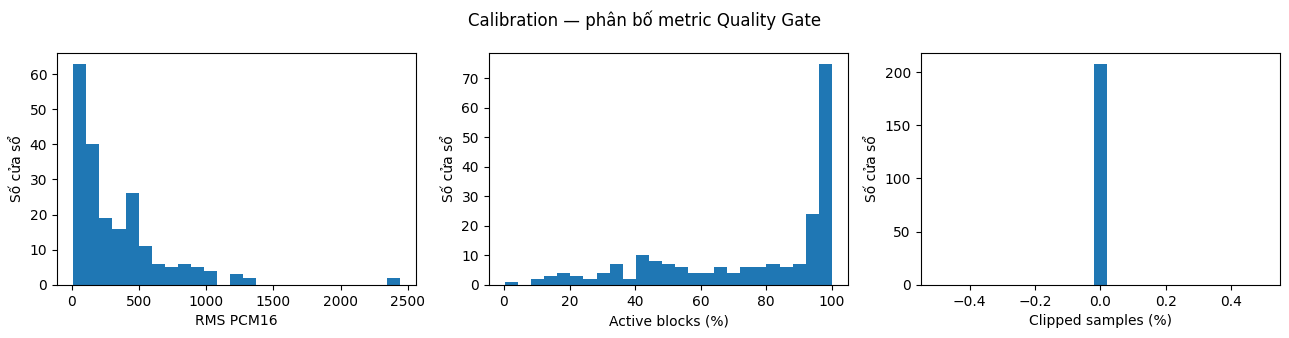

In [26]:
fig, ax = plt.subplots(1,3,figsize=(13,3.4))
for a, values, name in zip(ax, (c.rms, c.active_ratio*100, c.clipped_ratio*100),
                           ('RMS PCM16','Active blocks (%)','Clipped samples (%)')):
    a.hist(values, bins=25)
    a.set(xlabel=name, ylabel='Số cửa sổ')
fig.suptitle('Calibration — phân bố metric Quality Gate')
plt.tight_layout()
FIGURES.mkdir(parents=True,exist_ok=True)
fig.savefig(FIGURES/'calibration_quality_distributions.png',dpi=145,bbox_inches='tight')
plt.show()

## 1. Khảo sát trên Calibration

Quét 432 cấu hình để kiểm tra độ nhạy; chỉ so sánh **mức giữ Playback** và số cửa sổ `silence` bị chặn. Không tối ưu tùy tiện theo số lượng `AUDIO_OK` vì fan/podcast/room noise cũng có thể là âm thanh hợp lệ.

In [27]:
from itertools import product
mavs = np.stack(c.block_mav_json.map(json.loads)).astype(np.int32)
assert mavs.shape == (len(c),313)
rms, clipped = c.rms.to_numpy(), c.clipped_ratio.to_numpy()
quiet = c.subtype.eq('silence').to_numpy()
pb_a, pb_n = c.subtype.eq('playback_asthma').to_numpy(), c.subtype.eq('playback_non_asthma_disease').to_numpy()

def states(min_rms, mav_threshold, min_active_ratio, max_clip):
    active = (mavs > mav_threshold).mean(axis=1)
    return np.where(active < min_active_ratio,'AUDIO_INACTIVE',
           np.where(clipped > max_clip,'AUDIO_TOO_LOUD',
           np.where(rms < min_rms,'AUDIO_TOO_WEAK','AUDIO_OK')))

sweep_rows=[]
for mav_thr, ar, rmin, cmax in product((20,40,60,80,100,120),
                                       (.01,.03,.05,.10),
                                       (20.,50.,80.,120.,150.,200.),
                                       (.001,.005,.01)):
    s=states(rmin,mav_thr,ar,cmax)
    sweep_rows.append({'min_rms':rmin,'block_mav':mav_thr,'min_active_ratio':ar,
        'max_clipped_ratio':cmax,'playback_ok':int(np.sum((s=='AUDIO_OK')&(pb_a|pb_n))),
        'silence_inactive':int(np.sum((s=='AUDIO_INACTIVE')&quiet)),
        'rejected_total':int(np.sum(s!='AUDIO_OK'))})
sweep=pd.DataFrame(sweep_rows)
RESULTS.mkdir(exist_ok=True)
sweep.to_csv(RESULTS/'candidate_quality_sweep.csv',index=False)
rows=[]
for name, mav_thr, ar in [('V1',20,.01),('MAV40',40,.01),('MAV60',60,.01),
                          ('MAV80',80,.01),('MAV120',120,.01),('MAV100_AR5%',100,.05)]:
    s=states(20,mav_thr,ar,.01)
    rows.append({'candidate':name,'Asthma PB OK':f'{np.sum((s=="AUDIO_OK")&pb_a)}/{pb_a.sum()}',
                 'Non-Asthma PB OK':f'{np.sum((s=="AUDIO_OK")&pb_n)}/{pb_n.sum()}',
                 'Silence inactive':int(np.sum((s=='AUDIO_INACTIVE')&quiet)),
                 'Tổng rejected':int(np.sum(s!='AUDIO_OK'))})
print('Đã khảo sát',len(sweep),'cấu hình; lưu candidate_quality_sweep.csv')
display(pd.DataFrame(rows))

Đã khảo sát 432 cấu hình; lưu candidate_quality_sweep.csv


,candidate,Asthma PB OK,Non-Asthma PB OK,Silence inactive,Tổng rejected
0,V1,72/72,72/72,0,1
1,MAV40,72/72,72/72,0,1
2,MAV60,72/72,59/72,0,14
3,MAV80,70/72,55/72,0,20
4,MAV120,70/72,48/72,1,30
5,MAV100_AR5%,68/72,43/72,1,45


## 2. Cấu hình Quality Gate V1 được giữ lại

| Tham số | Giá trị | Quy tắc kiểm tra |
|---|---:|---|
| `min_rms` | **20** | `RMS ≥ 20` (đơn vị biên độ PCM16) |
| `active_block_threshold` | **20** | Một block hoạt động khi `MAV > 20` (MAV chia nguyên) |
| `min_active_ratio` | **0,01 (1%)** | Cần ít nhất **4/313 block** hoạt động trong 5 s |
| `max_clipped_ratio` | **0,01 (1%)** | Chấp nhận tỷ lệ mẫu clipping `≤ 1%` |
| `clip_level` | **32000** | Mẫu clipping nếu `abs(PCM16) > 32000` |
| `block_size` | **256 mẫu** | 312 block đủ + 1 block cuối 128 mẫu |

**Thứ tự quyết định:** `AUDIO_INACTIVE` → `AUDIO_TOO_LOUD` → `AUDIO_TOO_WEAK` → `AUDIO_OK`. Giữ V1 vì tái lập tốt trên Calibration và không loại các mẫu Playback ở phép thử hiện tại; đây **không phải chứng minh ngưỡng tối ưu**.

In [28]:
params=QualityThresholds(min_rms=20.0,active_block_threshold=20,
    min_active_ratio=.01,max_clipped_ratio=.01,clip_level=32000,block_size=256)
params.validate()
selected=states(params.min_rms,params.active_block_threshold,
                params.min_active_ratio,params.max_clipped_ratio)
preview=c[['subtype','source_group','file_name','crop_start_s','rms','clipped_ratio']].copy()
preview['active_ratio']=((mavs > params.active_block_threshold).mean(axis=1))
preview['state']=selected
print('Calibration:',preview.state.value_counts().to_dict())
print('Playback OK:',int(np.sum((selected=='AUDIO_OK')&(pb_a|pb_n))), '/',int((pb_a|pb_n).sum()))
display(preview.loc[preview.state!='AUDIO_OK'])
SELECTION_NOTE = ('Tái lập Quality Gate V1 từ Calibration: giữ được Playback PCM16; '
                  'ngưỡng block-MAV cao hơn loại thêm Playback. Không dùng Test để retune.')

Calibration: {'AUDIO_OK': 207, 'AUDIO_INACTIVE': 1}
Playback OK: 144 / 144


,subtype,source_group,file_name,crop_start_s,rms,clipped_ratio,active_ratio,state
45,room_noise,room_noise_session_01,room_noise_session_01.wav,41.8,11.630512,0.0,0.003195,AUDIO_INACTIVE


In [29]:
# BẬT True CHỈ SAU KHI SO SÁNH CALIBRATION với hồ sơ V1.
FREEZE_NOW=True
if FINAL.exists():
    frozen_params, meta=load_frozen(FINAL,file_sha256(MANIFEST))
    assert meta['calibration_metrics_sha256']==file_sha256(CAL), 'Calibration SHA đã thay đổi!'
    assert frozen_params==params, 'Ngưỡng hiện tại khác JSON FROZEN: không được âm thầm thay đổi'
    print('FROZEN hiện có hợp lệ:', FINAL)
elif FREEZE_NOW:
    summary={'calibration_windows':len(c), 'calibration_sessions':int(c.source_group.nunique()),
             'state_counts':{str(k):int(v) for k,v in preview.state.value_counts().items()}}
    freeze_config(FINAL,params,file_sha256(MANIFEST),file_sha256(CAL),SELECTION_NOTE,summary)
    print('Đã FROZEN:',FINAL)
else:
    print('Chưa freeze. Kiểm tra Calibration xong, đổi FREEZE_NOW=True và chạy lại cell này.')

FROZEN hiện có hợp lệ: D:\NCKH_2026\NCKH_2026_AIOT\Experiments_Benchmarking\Patient_Node\Final_V1_Validation\02_Quality_Check\results\final_quality_gate.json


## 3. Held-out Test — chỉ mở sau Freeze

Test dùng để báo cáo, **không** chọn lại ngưỡng. Nếu đã có `test_metrics.csv`, bắt buộc xác minh `test_metrics_provenance.json` và các SHA liên quan trước khi sử dụng.

In [30]:
RUN_HELDOUT_TEST=True
if not RUN_HELDOUT_TEST:
    print('Test đang khóa; bật RUN_HELDOUT_TEST=True sau Freeze.')
else:
    frozen_params, meta=load_frozen(FINAL,file_sha256(MANIFEST))
    assert frozen_params==params
    assert meta['calibration_metrics_sha256']==file_sha256(CAL)
    if not TEST.exists():
        subprocess.run([sys.executable,str(HERE/'Extract_Quality_Metrics.py'),'test',
                        '--repo-root',str(REPO_ROOT),'--manifest',str(MANIFEST)],check=True)
    verify_test_provenance(TEST,FINAL,MANIFEST,CAL)
    heldout=pd.read_csv(TEST)
    assert heldout.qc_split.eq('test').all()
    assert set(heldout.source_group).isdisjoint(set(c.source_group))
    print('Test:',heldout.final_state.value_counts().to_dict())
    display(pd.crosstab(heldout.subtype,heldout.final_state))
    display(heldout.loc[heldout.final_state!='AUDIO_OK',
          ['subtype','source_group','file_name','crop_start_s','rms','active_ratio','final_state']])
    print('Playback Test AUDIO_OK:',int((heldout.source_kind.eq('playback') &
          heldout.final_state.eq('AUDIO_OK')).sum()),'/',int(heldout.source_kind.eq('playback').sum()))

Test: {'AUDIO_OK': 21, 'AUDIO_INACTIVE': 1}


final_state,AUDIO_INACTIVE,AUDIO_OK
subtype,,
knock,0,2
playback_asthma,0,8
playback_non_asthma_disease,0,8
room_noise,1,1
speech,0,2


,subtype,source_group,file_name,crop_start_s,rms,active_ratio,final_state
2,room_noise,room_noise_session_06,room_noise_session_06.wav,9.9,14.774948,0.0,AUDIO_INACTIVE


Playback Test AUDIO_OK: 16 / 16


## 4. Đối chứng Silence bổ sung (tùy chọn, **sau Freeze**)

So sánh Silence cũ (`silence_old_01`), Silence mới `vad_silence_session_01.wav` **ngoài manifest**, và `room_noise_session_02`. Không gộp vào Test và không thay ngưỡng. Bật cell khi đã có WAV mới ở `extra_validation/`.

state,AUDIO_INACTIVE,AUDIO_OK,AUDIO_TOO_WEAK
source,,,
Room noise 02,0,12,0
Silence cũ,0,60,0
Silence mới,56,0,4


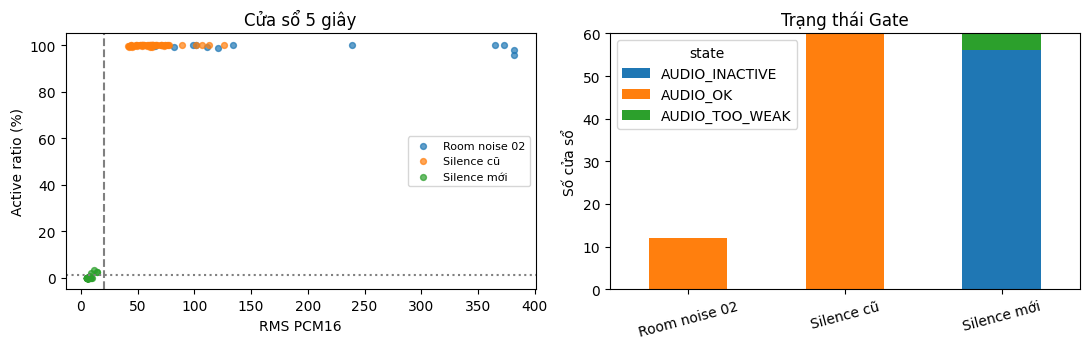

In [31]:
RUN_SUPPLEMENTAL=True
SILENCE_NEW_PATH=None  # hoặc Path(r'D:\...\vad_silence_session_01.wav')
if not RUN_SUPPLEMENTAL:
    print('Đối chứng bổ sung đang tắt.')
else:
    frozen_params,meta=load_frozen(FINAL,file_sha256(MANIFEST))
    assert meta['calibration_metrics_sha256']==file_sha256(CAL) and frozen_params==params
    def from_session(sid):
        found=m.loc[(m.session_id==sid)&(m.qc_split=='calibration'),'file_path'].unique()
        assert len(found)==1,(sid,len(found))
        return Path(found[0]).resolve()
    if SILENCE_NEW_PATH is None:
        roots=[HERE/'extra_validation',HERE.parent/'extra_validation',
               HERE.parent/'03_VAD_Trigger'/'extra_validation']
        matches=sorted({p.resolve() for root in roots if root.is_dir()
                        for p in root.rglob('vad_silence_session_01.wav')})
        assert len(matches)==1,'Cần đúng một WAV Silence mới ngoài manifest (hoặc đặt SILENCE_NEW_PATH)'
        silence_new=matches[0]
    else:
        silence_new=Path(SILENCE_NEW_PATH).expanduser().resolve()
        assert silence_new.name.casefold()=='vad_silence_session_01.wav' and silence_new.is_file()
    assert silence_new not in {Path(s).resolve() for s in m.file_path}
    sources={'Silence cũ':from_session('silence_old_01'),
             'Silence mới':silence_new,
             'Room noise 02':from_session('room_noise_session_02')}
    extra=[]
    for label,path in sources.items():
        with wave.open(str(path),'rb') as w:
            assert (w.getnchannels(),w.getsampwidth(),w.getframerate(),w.getcomptype())==(1,2,16000,'NONE')
            data=np.frombuffer(w.readframes(w.getnframes()),dtype='<i2')
        for idx,start in enumerate(range(0,len(data)-80000+1,80000),1):
            state,met=classify_audio(data[start:start+80000],frozen_params)
            extra.append({'source':label,'window':idx,'start_s':start/16000,
                          'state':state,'rms':met['rms'],
                          'active_ratio':met['active_ratio'],'clipped_ratio':met['clipped_ratio']})
    extra_df=pd.DataFrame(extra)
    folder=RESULTS/'supplemental_validation';folder.mkdir(parents=True,exist_ok=True)
    extra_df.to_csv(folder/'three_session_quality_windows.csv',index=False,encoding='utf-8-sig')
    display(pd.crosstab(extra_df.source,extra_df.state))
    fig,ax=plt.subplots(1,2,figsize=(11,3.6))
    for label,g in extra_df.groupby('source'):
        ax[0].scatter(g.rms,g.active_ratio*100,label=label,s=18,alpha=.7)
    ax[0].axvline(params.min_rms,ls='--',color='gray');ax[0].axhline(params.min_active_ratio*100,ls=':',color='gray')
    ax[0].set(xlabel='RMS PCM16',ylabel='Active ratio (%)',title='Cửa sổ 5 giây');ax[0].legend(fontsize=8)
    pd.crosstab(extra_df.source,extra_df.state).plot(kind='bar',stacked=True,ax=ax[1],rot=15)
    ax[1].set(xlabel='',ylabel='Số cửa sổ',title='Trạng thái Gate')
    plt.tight_layout();plt.show()

## Kết luận và bàn giao

**Giữ nguyên Quality Gate V1** theo bảng tham số ở mục 2, cấu hình đã được **FROZEN** trước khi đánh giá Held-out Test. Kết quả lần chạy này:

| Tập kiểm tra | Kết quả | Diễn giải |
|---|---:|---|
| Calibration | **207/208 `AUDIO_OK`** | 1 cửa sổ room noise bị đánh dấu `AUDIO_INACTIVE` |
| Held-out Test | **21/22 `AUDIO_OK`** | 1 cửa sổ room noise bị đánh dấu `AUDIO_INACTIVE` |
| Playback — Calibration | **144/144 `AUDIO_OK`** | Không loại mẫu Playback trong tập đã khảo sát |
| Playback — Test | **16/16 `AUDIO_OK`** | Kết quả giữ mẫu trên tập Test lịch sử |
| Silence cũ (đối chứng) | **60/60 `AUDIO_OK`** | Không chặn được Silence có nền nhiễu cao |
| Silence mới (đối chứng) | **60/60 bị chặn** | 56 `INACTIVE`, 4 `TOO_WEAK` |

**Giới hạn:** Quality Gate không phải VAD hay bộ phát hiện tiếng hô hấp; kết quả phụ thuộc điều kiện ghi âm. Chưa có đủ mẫu clipping thực tế để đánh giá ngưỡng `1%`. Các cửa sổ cùng session không được coi là các session độc lập. Kiểm thử Python chưa thay thế xác nhận tương đương với firmware `Quality_Check.cpp` trên ESP32-S3.

**Bàn giao:** giữ `final_quality_gate.json` cùng manifest, CSV Calibration/Test và provenance; chuyển sang **03_VAD_Trigger** để kiểm tra kích hoạt thu âm thực tế.